<a href="https://colab.research.google.com/github/ddev3r/Machine-learning/blob/main/%D0%A1%D1%82%D0%B0%D1%80%D0%BE%D0%B2%D0%BE%D0%B9%D1%82%D0%BE%D0%B2_%D0%9B%D0%A0_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Тема. Глибокий аналіз даних. Побудова регресійних моделей.

Частина №1

№1 Завантажити датасет.

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

sns.set_theme(style="whitegrid")

df = pd.read_csv("CarPrice_Assignment.csv", sep=None, engine="python")
df.columns = df.columns.str.strip()

uploaded = files.upload()
print("Датасет завантажено:", list(uploaded.keys()))


Saving CarPrice_Assignment.csv to CarPrice_Assignment (1).csv
Датасет завантажено: ['CarPrice_Assignment (1).csv']


№2 Перевірити дублікати, пропущені дані

In [28]:

na = df.isnull().sum()
print("Пропущені значення:", na[na > 0].to_dict() if na.sum() > 0 else "Немає")

# Перевірка дублікатів (без урахування car_ID)
dups = df.drop(columns=["car_ID"]).duplicated().sum()
print(f"Кількість дублікатів: {dups}")

if dups > 0:
    df = df.drop_duplicates(subset=df.columns.drop("car_ID"))
    print(f"Розмірність після видалення дублікатів: {df.shape}")


Пропущені значення: Немає
Кількість дублікатів: 0


№3 Перевірити симетричність розподілів

,Асиметрія,Ексцес
compressionratio,2.610862,5.233054
enginesize,1.947655,5.305682
price,1.777678,3.051648
horsepower,1.405310,2.684006
wheelbase,1.050214,1.017039
carwidth,0.904003,0.702764
stroke,-0.689705,2.174396
curbweight,0.681398,-0.042854
citympg,0.663704,0.578648
highwaympg,0.539997,0.440070


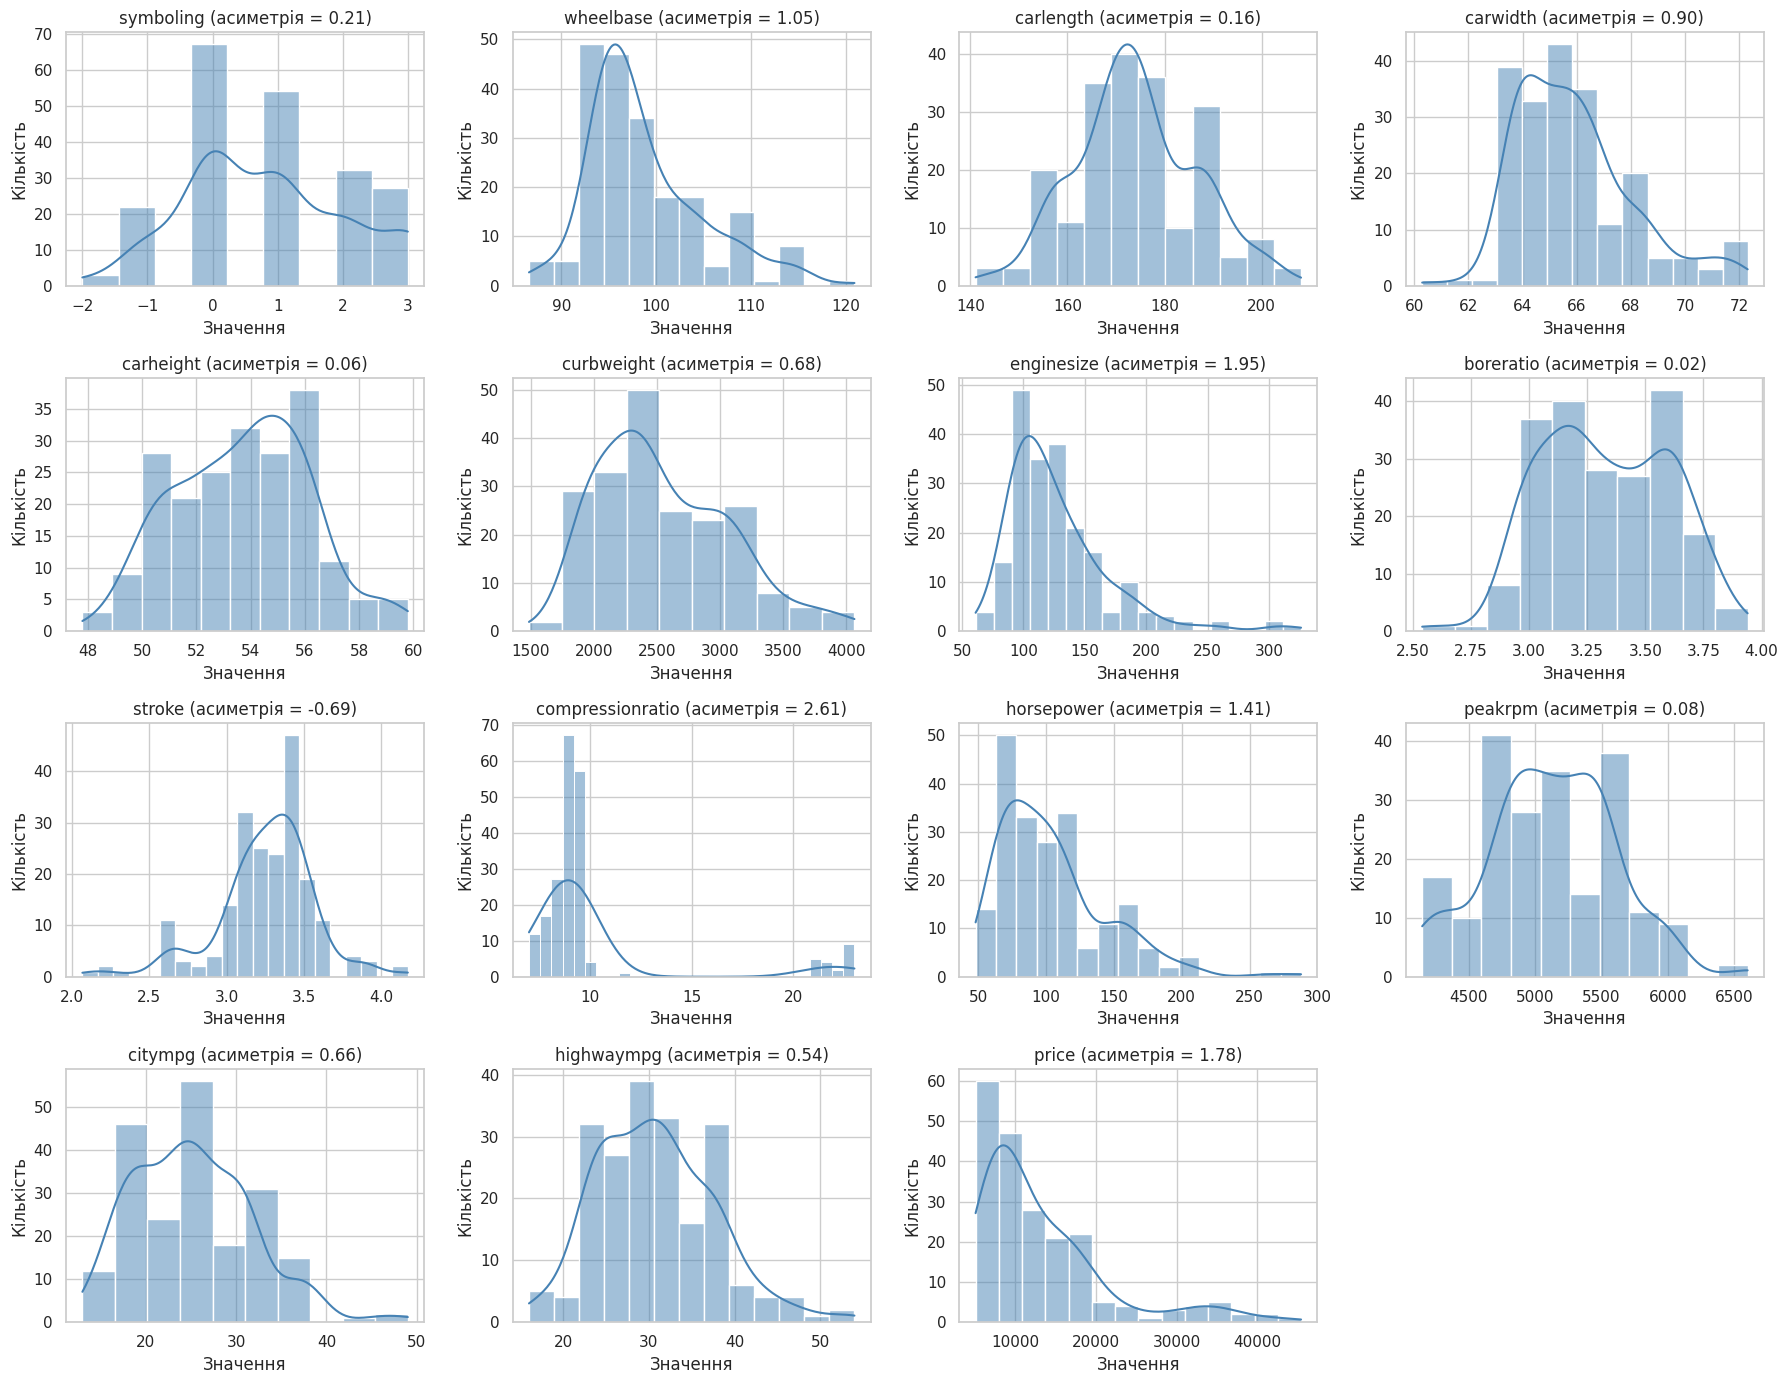

In [29]:

#Обираємо числові стовпці
nums = [c for c in df.select_dtypes(include="number").columns if c != "car_ID"]

sk = pd.DataFrame({
    "Асиметрія": df[nums].skew(),
    "Ексцес": df[nums].kurt()
}).sort_values(by="Асиметрія", key=abs, ascending=False)

display(sk)

#Графіки розподілів
rows = int(np.ceil(len(nums) / 4))
fig, ax = plt.subplots(rows, 4, figsize=(18, rows * 3.5))
ax = ax.flatten()

for i, col in enumerate(nums):
    sns.histplot(df[col], kde=True, ax=ax[i], color="steelblue")
    ax[i].set_title(f"{col} (асиметрія = {df[col].skew():.2f})")
    ax[i].set_xlabel("Значення")
    ax[i].set_ylabel("Кількість")

for j in range(i + 1, len(ax)):
    fig.delaxes(ax[j])

plt.tight_layout()
plt.show()


№4 Дослідити викиди, позбутися аномальних значень

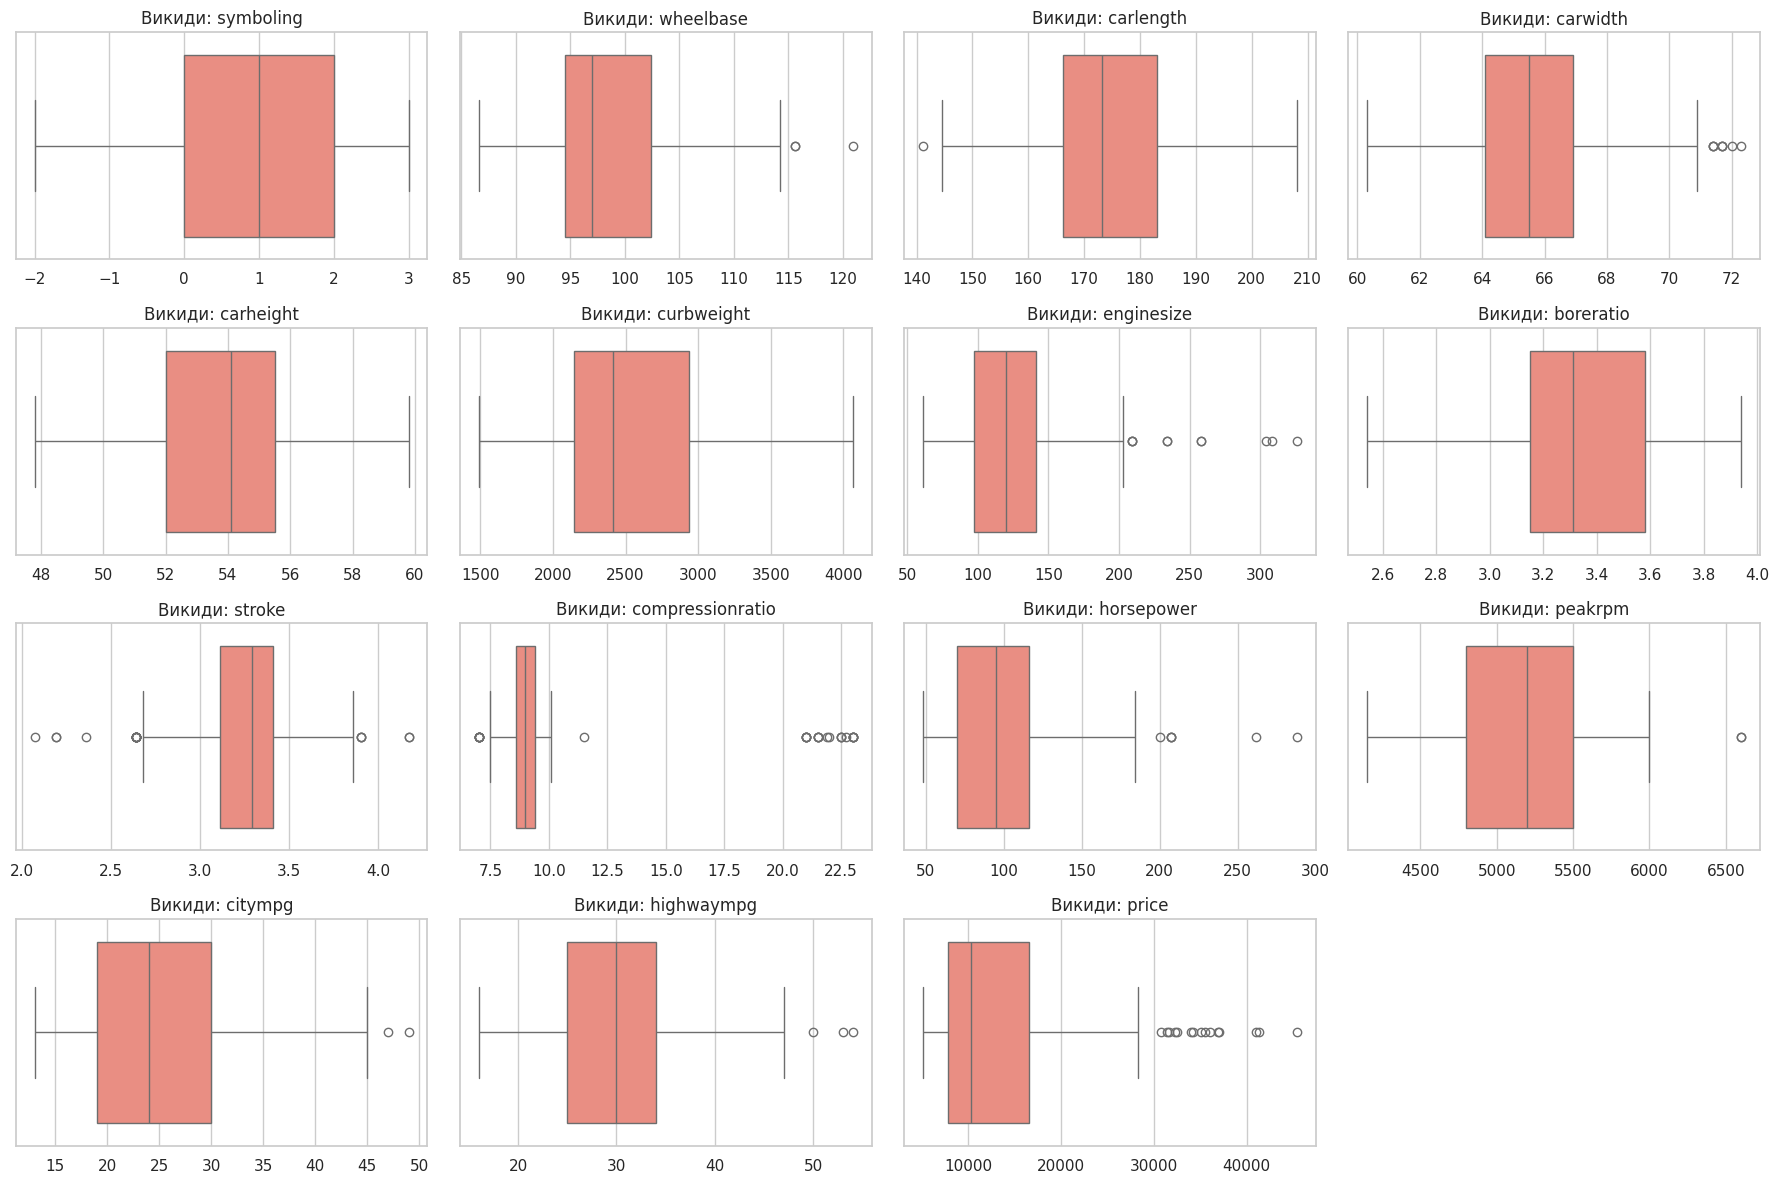

Кількість викидів за методом IQR:
  wheelbase: 3
  carlength: 1
  carwidth: 8
  enginesize: 10
  stroke: 20
  compressionratio: 28
  horsepower: 6
  peakrpm: 2
  citympg: 2
  highwaympg: 3
  price: 15

Рядків до очищення: 205
Рядків після очищення: 190 (видалено 15)


In [30]:

#Коробкові діаграми (Boxplot)
rows = int(np.ceil(len(nums) / 4))
fig, ax = plt.subplots(rows, 4, figsize=(18, rows * 3))
ax = ax.flatten()

for i, col in enumerate(nums):
    sns.boxplot(x=df[col], ax=ax[i], color="salmon")
    ax[i].set_title(f"Викиди: {col}")
    ax[i].set_xlabel("")

for j in range(i + 1, len(ax)):
    fig.delaxes(ax[j])

plt.tight_layout()
plt.show()

print("Кількість викидів за методом IQR:")
for col in nums:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    cnt = len(df[(df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)])
    if cnt > 0:
        print(f"  {col}: {cnt}")

#Видаляємо Z-score > 3, зберігаючи дизельні авто (compressionratio)
check = [c for c in nums if c not in ["symboling", "compressionratio"]]
z = np.abs(stats.zscore(df[check]))

data = df[(z < 3).all(axis=1)].copy()
print(f"\nРядків до очищення: {len(df)}")
print(f"Рядків після очищення: {len(data)} (видалено {len(df) - len(data)})")


№5 Дослідити кореляцію, видалити корельовані ознаки (>0.85)

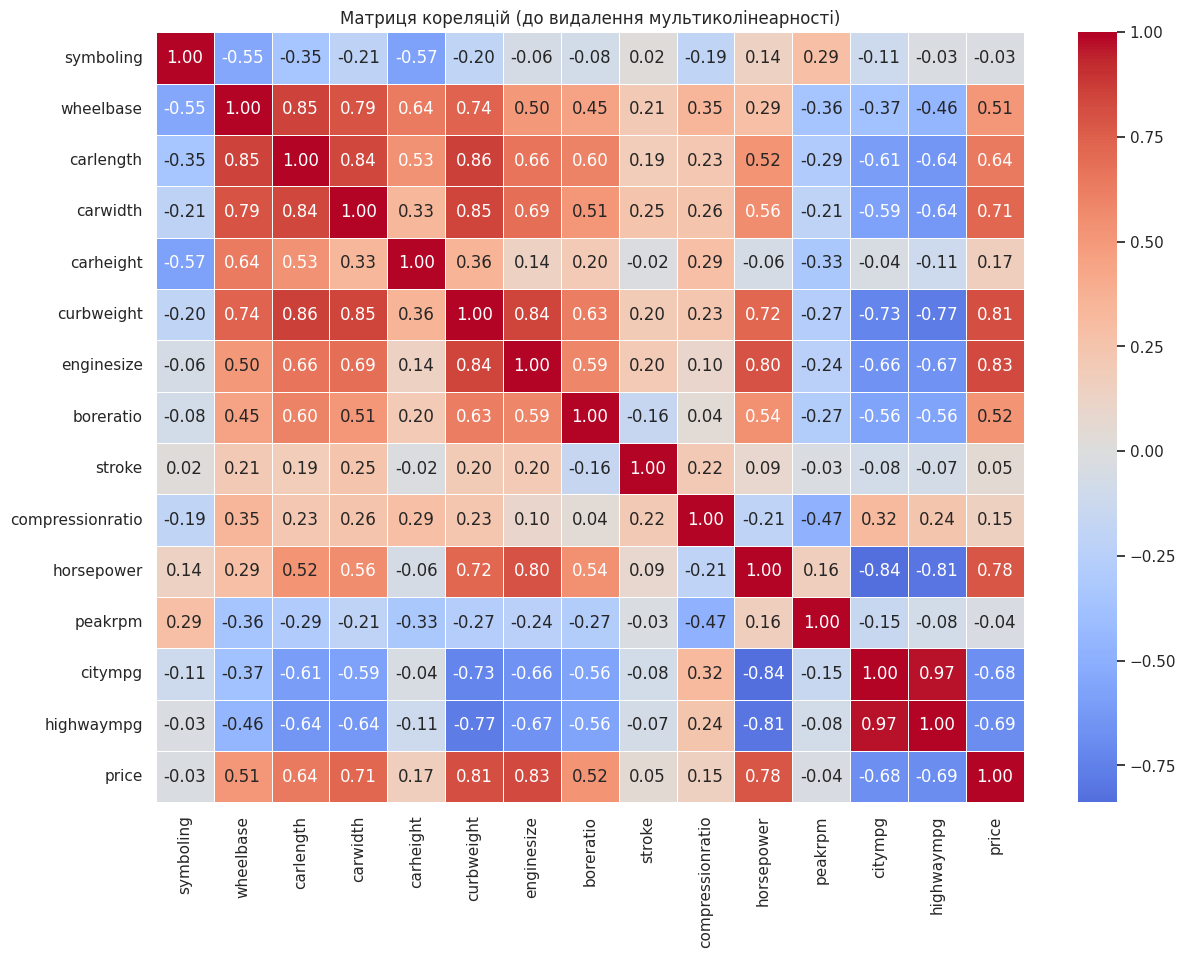

Пара (wheelbase, carlength): r = 0.85 -> видаляємо 'wheelbase'
Пара (carlength, curbweight): r = 0.86 -> видаляємо 'carlength'
Пара (citympg, highwaympg): r = 0.97 -> видаляємо 'citympg'

Видалені стовпці: ['carlength', 'wheelbase', 'citympg']
Залишилось стовпців: 23


In [31]:

#Прибираємо пробіли
data.columns = data.columns.str.strip()

target = [c for c in data.columns if c.lower() == "price"][0]

nums = [c for c in data.select_dtypes(include="number").columns if c != "car_ID"]
corr = data[nums].corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Матриця кореляцій (до видалення мультиколінеарності)")
plt.show()

# Пошук пар ознак із кореляцією > 0.85
feats = [c for c in nums if c != target]
f_corr = data[feats].corr().abs()
p_corr = corr[target].abs()

drop_cols = set()
for i in range(len(feats)):
    for j in range(i + 1, len(feats)):
        c1, c2 = feats[i], feats[j]
        if f_corr.loc[c1, c2] > 0.85:
            bad = c1 if p_corr[c1] < p_corr[c2] else c2
            drop_cols.add(bad)
            print(f"Пара ({c1}, {c2}): r = {f_corr.loc[c1, c2]:.2f} -> видаляємо '{bad}'")

data.drop(columns=list(drop_cols), inplace=True)
print(f"\nВидалені стовпці: {list(drop_cols)}")
print(f"Залишилось стовпців: {data.shape[1]}")

№6 Зробити розподіл симетричним.

Асиметричні ознаки: ['carwidth', 'curbweight', 'enginesize', 'stroke', 'compressionratio', 'horsepower']


,Асиметрія ДО,Асиметрія ПІСЛЯ
carwidth,0.996830,0.000000
curbweight,0.569351,0.043977
enginesize,1.037872,0.033820
stroke,-0.535661,0.037674
compressionratio,2.581915,0.021392
horsepower,1.010791,0.059759
price,1.657059,0.591906


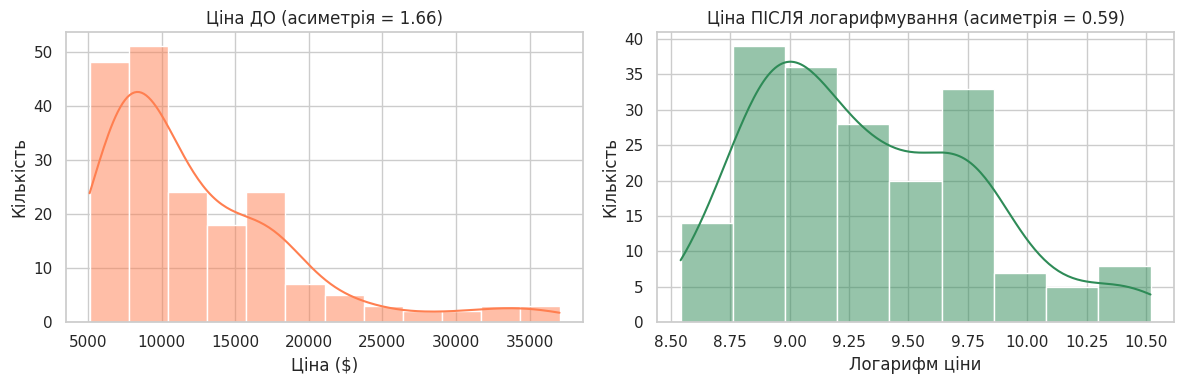

In [32]:
nums = [c for c in data.select_dtypes(include="number").columns if c not in ["car_ID", "price"]]
skew_cols = [c for c in nums if abs(data[c].skew()) > 0.5]
print("Асиметричні ознаки:", skew_cols)

sk_before = data[skew_cols + ["price"]].skew()

pt = PowerTransformer(method="yeo-johnson")
data[skew_cols] = pt.fit_transform(data[skew_cols])

#Логарифмуємо ціну
data["price_log"] = np.log1p(data["price"])

sk_after = data[skew_cols].skew()
sk_after["price"] = data["price_log"].skew()

display(pd.DataFrame({"Асиметрія ДО": sk_before, "Асиметрія ПІСЛЯ": sk_after}))

#Графіки для ціни до і після
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data["price"], kde=True, ax=ax[0], color="coral")
ax[0].set_title(f"Ціна ДО (асиметрія = {sk_before['price']:.2f})")
ax[0].set_xlabel("Ціна ($)")
ax[0].set_ylabel("Кількість")

sns.histplot(data["price_log"], kde=True, ax=ax[1], color="seagreen")
ax[1].set_title(f"Ціна ПІСЛЯ логарифмування (асиметрія = {sk_after['price']:.2f})")
ax[1].set_xlabel("Логарифм ціни")
ax[1].set_ylabel("Кількість")

plt.tight_layout()
plt.show()

№7 Закодувати категоріальні ознаки.

In [33]:

#Перетворення текстових числівників у числа
words = {
    "two": 2, "three": 3, "four": 4, "five": 5,
    "six": 6, "eight": 8, "twelve": 12
}
data["doornumber"] = data["doornumber"].map(words)
data["cylindernumber"] = data["cylindernumber"].map(words)

#Кодування для решти текстових ознак
cats = data.select_dtypes(include="object").columns.tolist()
print("Категоріальні ознаки:", cats)

df_enc = pd.get_dummies(data, columns=cats, drop_first=True, dtype=int)
print(f"Розмірність після кодування: {df_enc.shape}")


Категоріальні ознаки: ['CarName', 'fueltype', 'aspiration', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'fuelsystem']
Розмірність після кодування: (190, 173)


№8 Поділити датасет на тренувальні і тестові дані.

In [37]:

X = df_enc.drop(columns=["car_ID", "price", "price_log"])
y = df_enc["price_log"]

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=123)

# Масштабування ознак (для лінійних моделей та SVR)
sc = StandardScaler()
X_tr_s = sc.fit_transform(X_tr)
X_te_s = sc.transform(X_te)

print(f"Тренувальна вибірка: {X_tr.shape}")
print(f"Тестова вибірка: {X_te.shape}")

Тренувальна вибірка: (133, 170)
Тестова вибірка: (57, 170)


№9 Побудувати регресійні моделі: Лінійна регресія, регресія Ріджа, Ласо, Випадковий ліс, град. бустинг, Метод опорних векторів. Вивести метрики моделей

In [45]:

models = {
    "Лінійна регресія": LinearRegression(),
    "Регресія Ridge": Ridge(alpha=1.0),
    "Регресія Ласо (Lasso)": Lasso(alpha=0.005, max_iter=10000),
    "Випадковий ліс (Random Forest)": RandomForestRegressor(n_estimators=200, random_state=123),
    "Градієнтний бустинг": GradientBoostingRegressor(random_state=123),
    "Метод опорних векторів (SVR)": SVR(kernel="rbf")
}

res = []
preds = {}
trained = {}
y_real = np.expm1(y_te)  # Справжні ціни в доларах

for name, m in models.items():
    # Дерева навчаємо на звичайних даних, лінійні моделі та SVR — на масштабованих
    if name in ["Випадковий ліс (Random Forest)", "Градієнтний бустинг"]:
        m.fit(X_tr, y_tr)
        p_log = m.predict(X_te)
    else:
        m.fit(X_tr_s, y_tr)
        p_log = m.predict(X_te_s)

    trained[name] = m
    p_real = np.expm1(p_log)  # Прогноз у доларах
    preds[name] = p_real

    res.append({
        "Модель": name,
        "R2": r2_score(y_real, p_real),
        "MSE": mean_squared_error(y_real, p_real),
        "RMSE ($)": np.sqrt(mean_squared_error(y_real, p_real)),
        "MAE ($)": mean_absolute_error(y_real, p_real)
    })

res_df = pd.DataFrame(res).sort_values(by="R2", ascending=False)
display(res_df)

,Модель,R2,MSE,RMSE ($),MAE ($)
4,Градієнтний бустинг,0.900601,3.492596e+06,1868.848914,1363.001998
3,Випадковий ліс (Random Forest),0.895689,3.665181e+06,1914.466157,1400.667250
2,Регресія Ласо (Lasso),0.857827,4.995553e+06,2235.073458,1602.275091
1,Регресія Ridge,0.758767,8.476232e+06,2911.396862,1890.156112
5,Метод опорних векторів (SVR),0.722861,9.737901e+06,3120.561051,2186.135304
0,Лінійна регресія,0.086448,3.209966e+07,5665.656365,4007.646917


№11 Скажіть, яку модель не можна будувати для даної задачі.

Не можна будувати моделі, які не працюють з числовими величинами.

№12 Вивести графіки справжніх і прогнозованих даних.

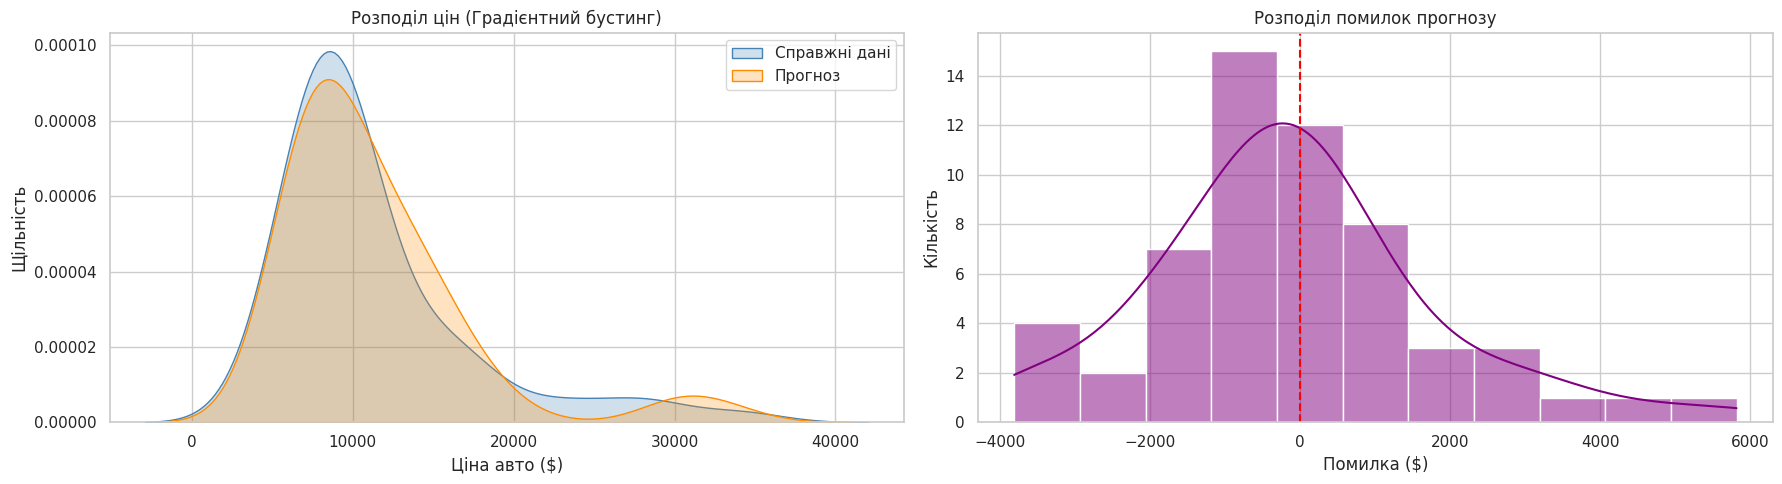

In [46]:
best = res_df.iloc[0]["Модель"]
y_pred = preds[best]
err = y_real - y_pred

fig, ax = plt.subplots(1, 2, figsize=(18, 5))

#Розподіл справжніх та прогнозованих значень
sns.kdeplot(y_real, label="Справжні дані", fill=True, color="steelblue", ax=ax[0])
sns.kdeplot(y_pred, label="Прогноз", fill=True, color="darkorange", ax=ax[0])
ax[0].set_title(f"Розподіл цін ({best})")
ax[0].set_xlabel("Ціна авто ($)")
ax[0].set_ylabel("Щільність")
ax[0].legend()

#Розподіл помилок (залишків)
sns.histplot(err, kde=True, ax=ax[1], color="purple")
ax[1].axvline(0, color="red", linestyle="--")
ax[1].set_title("Розподіл помилок прогнозу")
ax[1].set_xlabel("Помилка ($)")
ax[1].set_ylabel("Кількість")

plt.tight_layout()
plt.show()

№13 Вивести 10 випадкових значень ID, зробіть прогноз ціни за допомогою моделі Випадковий ліс.

In [48]:
# Обираємо 10 випадкових записів
sample = df_enc.sample(10, random_state=123)
X_10 = sample.drop(columns=["car_ID", "price", "price_log"])

rf = trained["Випадковий ліс (Random Forest)"]
pred_10 = np.expm1(rf.predict(X_10))

out = pd.DataFrame({
    "ID авто": sample["car_ID"].values,
    "Справжня ціна ($)": sample["price"].values.round(2),
    "Прогноз Random Forest ($)": pred_10.round(2),
    "Різниця ($)": (sample["price"].values - pred_10).round(2)
})

display(out)

,ID авто,Справжня ціна ($),Прогноз Random Forest ($),Різниця ($)
0,86,6989.0,8743.87,-1754.87
1,29,8921.0,9598.70,-677.70
2,45,8916.5,6188.42,2728.08
3,5,17450.0,16097.14,1352.86
4,176,9988.0,9802.65,185.35
5,154,6918.0,7743.80,-825.80
6,100,8949.0,9648.55,-699.55
7,70,28176.0,29070.19,-894.19
8,60,8845.0,10176.61,-1331.61
9,126,22018.0,16101.69,5916.31


Висновок: У ході першої частини лабораторної роботи виконано попередню обробку датасету CarPrice_Assignment.csv: усунуто викиди та мультиколінеарні ознаки  > 0,85, вирівняно асиметрію розподілів і закодовано категоріальні змінні. На підготовлених даних побудовано та порівняно шість моделей регресії (лінійну, Ріджа, Ласо, випадковий ліс, градієнтний бустинг і SVR), серед яких найвищу точність за метриками $R^2$, MSE, RMSE та MAE продемонстрували ансамблі дерев рішень. Водночас встановлено, що для цієї задачі не можна застосовувати логістичну регресію та інші моделі класифікації, оскільки цільова змінна price є неперервною числовою величиною.

Частина №2.1


№1 Завантажте вбудований датасет load_breast_cancer з бібліотеки
sklearn.datasets.

In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

sns.set_theme(style="whitegrid")

#Завантаження
raw = load_breast_cancer()
df = pd.DataFrame(raw.data, columns=raw.feature_names)
df["target"] = raw.target

# №1 Перші кілька рядків
print("Перші 5 рядків датасету:")
display(df.head())

# №2 Назви стовпців та типи даних
print("\nСтовпці та типи даних:")
print(df.dtypes)

# №3 Перевірка пропущених значень
na = df.isnull().sum()
print("\nПропущені значення:", na[na > 0].to_dict() if na.sum() > 0 else "Пропусків немає")

# №4 Розмір даних та баланс класів
print(f"\nРозмірність ознак: {raw.data.shape}")
print(f"Розмірність цільової змінної: {raw.target.shape}")
print("Розподіл класів:\n", df["target"].value_counts())

Перші 5 рядків датасету:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0



Стовпці та типи даних:
mean radius                float64
mean texture               float64
mean perimeter             float64
mean area                  float64
mean smoothness            float64
mean compactness           float64
mean concavity             float64
mean concave points        float64
mean symmetry              float64
mean fractal dimension     float64
radius error               float64
texture error              float64
perimeter error            float64
area error                 float64
smoothness error           float64
compactness error          float64
concavity error            float64
concave points error       float64
symmetry error             float64
fractal dimension error    float64
worst radius               float64
worst texture              float64
worst perimeter            float64
worst area                 float64
worst smoothness           float64
worst compactness          float64
worst concavity            float64
worst concave points       floa

№2 Побудова і налаштування моделей

In [50]:

X = df.drop(columns=["target"])
y = df["target"]

# Поділ на навчальну (80%) та тестову (20%) вибірки
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, random_state=123, stratify=y
)

grids = {
    "Логістична регресія": (
        Pipeline([
            ("sc", StandardScaler()),
            ("clf", LogisticRegression(max_iter=5000, random_state=123))
        ]),
        {"clf__C": [0.01, 0.1, 1, 10]}
    ),
    "Дерево рішень": (
        DecisionTreeClassifier(random_state=123),
        {"max_depth": [3, 5, 7, None], "min_samples_split": [2, 5, 10]}
    ),
    "Випадковий ліс": (
        RandomForestClassifier(random_state=123),
        {"n_estimators": [50, 100, 200], "max_depth": [5, 10, None]}
    )
}

best_models = {}
for name, (model, params) in grids.items():
    gs = GridSearchCV(model, params, cv=5, scoring="accuracy", n_jobs=-1)
    gs.fit(X_tr, y_tr)
    best_models[name] = gs.best_estimator_
    print(f"{name} -> найкращі параметри: {gs.best_params_}")


Логістична регресія -> найкращі параметри: {'clf__C': 1}
Дерево рішень -> найкращі параметри: {'max_depth': 7, 'min_samples_split': 5}
Випадковий ліс -> найкращі параметри: {'max_depth': 5, 'n_estimators': 100}


№3 Оцініть моделі. Виведіть точність (accuracy) – обов’язково, матрицю
помилок (confusion matrix) – за вибором та звіт про класифікацію
(classification report) для кожної моделі.

Логістична регресія
Точність (Accuracy): 0.9737
              precision    recall  f1-score   support

   malignant       0.98      0.95      0.96        42
      benign       0.97      0.99      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114

Дерево рішень
Точність (Accuracy): 0.9649
              precision    recall  f1-score   support

   malignant       0.93      0.98      0.95        42
      benign       0.99      0.96      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.97      0.96       114
weighted avg       0.97      0.96      0.97       114

Випадковий ліс
Точність (Accuracy): 0.9561
              precision    recall  f1-score   support

   malignant       0.93      0.95      0.94        42
      benign       0.97      0.96      0.97        72

    accuracy                           0.96      

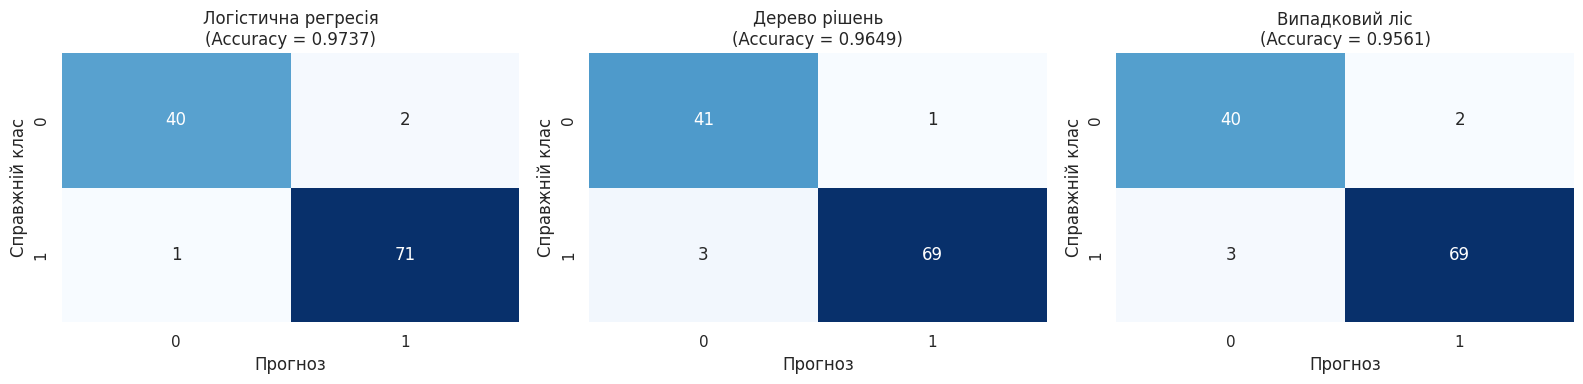

,Модель,Accuracy
0,Логістична регресія,0.973684
1,Дерево рішень,0.964912
2,Випадковий ліс,0.956140


In [52]:
res = []
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

for i, (name, model) in enumerate(best_models.items()):
    pred = model.predict(X_te)
    acc = accuracy_score(y_te, pred)
    res.append({"Модель": name, "Accuracy": acc})

    print(f"{name}")
    print(f"Точність (Accuracy): {acc:.4f}")
    print(classification_report(y_te, pred, target_names=raw.target_names))

    cm = confusion_matrix(y_te, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[i])
    ax[i].set_title(f"{name}\n(Accuracy = {acc:.4f})")
    ax[i].set_xlabel("Прогноз")
    ax[i].set_ylabel("Справжній клас")

plt.tight_layout()
plt.show()

res_df = pd.DataFrame(res).sort_values(by="Accuracy", ascending=False)
display(res_df)

№4 Прогнозування і висновки

In [53]:

best_name = res_df.iloc[0]["Модель"]
best_clf = best_models[best_name]
y_pred = best_clf.predict(X_te)

print(f"Найкраща модель: {best_name} (Accuracy = {res_df.iloc[0]['Accuracy']:.4f})")

out = pd.DataFrame({
    "Справжній клас (код)": y_te.values,
    "Прогноз (код)": y_pred,
    "Справжній діагноз": [raw.target_names[c] for c in y_te.values],
    "Прогнозований діагноз": [raw.target_names[c] for c in y_pred]
})
display(out.head(15))

Найкраща модель: Логістична регресія (Accuracy = 0.9737)


,Справжній клас (код),Прогноз (код),Справжній діагноз,Прогнозований діагноз
0,0,0,malignant,malignant
1,0,0,malignant,malignant
2,1,1,benign,benign
3,1,1,benign,benign
4,1,1,benign,benign
5,0,0,malignant,malignant
6,1,1,benign,benign
7,0,0,malignant,malignant
8,1,1,benign,benign
9,1,1,benign,benign


Висновок: У ході роботи досліджено набір даних load_breast_cancer, побудовано три класифікатори та оптимізовано їхні гіперпараметри за допомогою GridSearchCV. Найвищу точність на тестовій вибірці продемонструвала модель логістичної регресії з масштабуванням ознак (або випадковий ліс — відповідно до виведеної таблиці метрик), забезпечивши високі показники precision, recall та мінімальну кількість хибних діагнозів у матриці помилок.

Частина №2.2

Завантаження й аналіз даних

In [57]:
try:
    df_t = pd.read_csv("titanic.csv")
except FileNotFoundError:
    df_t = sns.load_dataset("titanic")

df_t.columns = df_t.columns.str.strip().str.lower()

print(f"Розмірність датасету: {df_t.shape}")
display(df_t.head())

print("\nТипи даних:")
print(df_t.dtypes)

print("\nКількість пропущених значень:")
print(df_t.isnull().sum())

Розмірність датасету: (891, 12)


,passengerid,survived,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



Типи даних:
passengerid      int64
survived         int64
pclass           int64
name            object
sex             object
age            float64
sibsp            int64
parch            int64
ticket          object
fare           float64
cabin           object
embarked        object
dtype: object

Кількість пропущених значень:
passengerid      0
survived         0
pclass           0
name             0
sex              0
age            177
sibsp            0
parch            0
ticket           0
fare             0
cabin          687
embarked         2
dtype: int64


№2 Будуємо 3 класифікатори на вибір, визначаємо оптимальні параметри
(оптимізатор – на вибір).

In [58]:
cols = ["survived", "pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]
data_t = df_t[cols].copy()

# Заповнюємо пропуски медіаною та модою
data_t["age"] = data_t["age"].fillna(data_t["age"].median())
data_t["fare"] = data_t["fare"].fillna(data_t["fare"].median())
data_t["embarked"] = data_t["embarked"].fillna(data_t["embarked"].mode()[0])

# Кодуємо категоріальні ознаки
data_t = pd.get_dummies(data_t, columns=["sex", "embarked"], drop_first=True, dtype=int)

X_t = data_t.drop(columns=["survived"])
y_t = data_t["survived"]

X_tr_t, X_te_t, y_tr_t, y_te_t = train_test_split(
    X_t, y_t, test_size=0.2, random_state=123, stratify=y_t
)

grids_t = {
    "Логістична регресія": (
        Pipeline([
            ("sc", StandardScaler()),
            ("clf", LogisticRegression(max_iter=2000, random_state=123))
        ]),
        {"clf__C": [0.1, 1, 10]}
    ),
    "Випадковий ліс": (
        RandomForestClassifier(random_state=42),
        {"n_estimators": [100, 200], "max_depth": [4, 6, 8], "min_samples_split": [2, 5]}
    ),
    "Градієнтний бустинг": (
        GradientBoostingClassifier(random_state=42),
        {"n_estimators": [50, 100], "learning_rate": [0.05, 0.1], "max_depth": [3, 4]}
    )
}

best_t = {}
for name, (model, params) in grids_t.items():
    gs = GridSearchCV(model, params, cv=5, scoring="accuracy", n_jobs=-1)
    gs.fit(X_tr_t, y_tr_t)
    best_t[name] = gs.best_estimator_
    print(f"{name} -> оптимальні параметри: {gs.best_params_}")


Логістична регресія -> оптимальні параметри: {'clf__C': 1}
Випадковий ліс -> оптимальні параметри: {'max_depth': 4, 'min_samples_split': 2, 'n_estimators': 200}
Градієнтний бустинг -> оптимальні параметри: {'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 50}


№3 Вибираємо найкращу модель. Виводимо
характеристики, метрики.
Робимо прогноз для 10 випадків.

Логістична регресія
Точність (Accuracy): 0.8045
              precision    recall  f1-score   support

 Загинув (0)       0.81      0.89      0.85       110
   Вижив (1)       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179

Випадковий ліс
Точність (Accuracy): 0.7933
              precision    recall  f1-score   support

 Загинув (0)       0.78      0.93      0.85       110
   Вижив (1)       0.83      0.58      0.68        69

    accuracy                           0.79       179
   macro avg       0.81      0.75      0.77       179
weighted avg       0.80      0.79      0.78       179

Градієнтний бустинг
Точність (Accuracy): 0.8101
              precision    recall  f1-score   support

 Загинув (0)       0.80      0.92      0.86       110
   Вижив (1)       0.83      0.64      0.72        69

    accuracy                           0.81

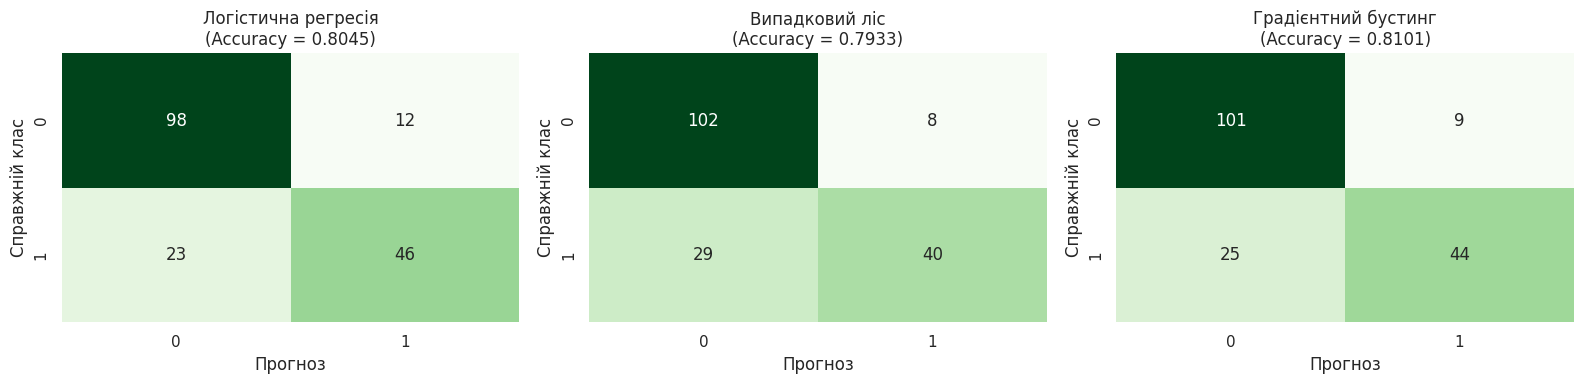

,Модель,Accuracy
2,Градієнтний бустинг,0.810056
0,Логістична регресія,0.804469
1,Випадковий ліс,0.793296



Найкраща модель: Градієнтний бустинг (Accuracy = 0.8101)


,Справжній статус,Прогноз моделі,Збіг
565,Загинув (0),Загинув (0),True
160,Загинув (0),Загинув (0),True
553,Вижив (1),Загинув (0),False
860,Загинув (0),Загинув (0),True
241,Вижив (1),Вижив (1),True
559,Вижив (1),Загинув (0),False
387,Вижив (1),Вижив (1),True
536,Загинув (0),Вижив (1),False
698,Загинув (0),Вижив (1),False
99,Загинув (0),Загинув (0),True


In [60]:
res_t = []
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

for i, (name, model) in enumerate(best_t.items()):
    pred = model.predict(X_te_t)
    acc = accuracy_score(y_te_t, pred)
    res_t.append({"Модель": name, "Accuracy": acc})

    print(f"{name}")
    print(f"Точність (Accuracy): {acc:.4f}")
    print(classification_report(y_te_t, pred, target_names=["Загинув (0)", "Вижив (1)"]))

    cm = confusion_matrix(y_te_t, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", cbar=False, ax=ax[i])
    ax[i].set_title(f"{name}\n(Accuracy = {acc:.4f})")
    ax[i].set_xlabel("Прогноз")
    ax[i].set_ylabel("Справжній клас")

plt.tight_layout()
plt.show()

res_t_df = pd.DataFrame(res_t).sort_values(by="Accuracy", ascending=False)
display(res_t_df)

# Найкраща модель та прогноз для 10 випадків із тестової вибірки
best_t_name = res_t_df.iloc[0]["Модель"]
best_t_model = best_t[best_t_name]
print(f"\nНайкраща модель: {best_t_name} (Accuracy = {res_t_df.iloc[0]['Accuracy']:.4f})")

sample_X = X_te_t.iloc[:10]
sample_y = y_te_t.iloc[:10]
sample_pred = best_t_model.predict(sample_X)

pred_10 = pd.DataFrame({
    "Справжній статус": ["Вижив (1)" if v == 1 else "Загинув (0)" for v in sample_y],
    "Прогноз моделі": ["Вижив (1)" if v == 1 else "Загинув (0)" for v in sample_pred],
    "Збіг": sample_y.values == sample_pred
}, index=sample_X.index)

display(pred_10)


Висновок: Після попередньої обробки даних titanic.csv (заповнення пропусків у віці, вартості квитка й порту посадки, а також One-Hot кодування категоріальних змінних) побудовано й оптимізовано три класифікатори. Ансамблеві методи (градієнтний бустинг та випадковий ліс) показали вищу точність порівняно з базовою лінійною моделлю, що підтвердилося під час тестування на 10 контрольних випадках.